# Stage 6: Connections Between Research Directions

We want to investigate whether related NLP research directions could suggest potential areas worth exploring for academic cooperation.

## 1. Finding research topics with high similarity

In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Load existing artifacts
artifacts = Path("artifacts")
if not artifacts.exists():
    artifacts = Path("../artifacts")

kmeans = joblib.load(artifacts / "final_kmeans_160.joblib")
profiles = pd.read_csv(
    artifacts / "final_cluster_profiles.csv"
).set_index("cluster_id")

# Compute pairwise cosine similarity between cluster centroids
similarity = cosine_similarity(kmeans.cluster_centers_)

# Select the 12 most similar unique pairs (excluding self-pairs)
i, j = np.triu_indices_from(similarity, k=1)
top_idx = np.argsort(similarity[i, j])[-12:][::-1]

# Display similarity and characteristic keywords
pairs = pd.DataFrame([
    {
        "Cluster A": int(i[t]),
        "Cluster B": int(j[t]),
        "Cosine similarity": round(float(similarity[i[t], j[t]]), 3),
        "Keywords A": profiles.loc[i[t], "top_terms"],
        "Keywords B": profiles.loc[j[t], "top_terms"]
    }
    for t in top_idx
])

with pd.option_context("display.max_colwidth", None):
    display(pairs)


,Cluster A,Cluster B,Cosine similarity,Keywords A,Keywords B
0,147,149,0.886,"reasoning, logical, llms, logical reasoning, models, language, logic, symbolic, commonsense, language models, tasks, large language","reasoning, models, reasoning models, thinking, llms, lrms, step, model, tasks, large, capabilities, accuracy"
1,55,149,0.885,"reasoning, cot, thought, chain, chain thought, thought cot, models, llms, step, cot reasoning, steps, language","reasoning, models, reasoning models, thinking, llms, lrms, step, model, tasks, large, capabilities, accuracy"
2,32,55,0.864,"cot, reasoning, thought, chain, chain thought, prompting, thought cot, llms, cot prompting, models, cot reasoning, step","reasoning, cot, thought, chain, chain thought, thought cot, models, llms, step, cot reasoning, steps, language"
3,11,128,0.843,"medical, clinical, patient, llms, healthcare, diagnosis, diagnostic, models, reasoning, patients, language, large","medical, llms, models, healthcare, domain, knowledge, medical knowledge, language, medical domain, large, clinical, med"
4,22,72,0.839,"asr, speech, speech recognition, recognition, automatic speech, recognition asr, automatic, asr systems, wer, error, model, asr models","speech, speech recognition, recognition, asr, automatic speech, automatic, model, data, recognition asr, supervised, self supervised, training"
5,72,140,0.817,"speech, speech recognition, recognition, asr, automatic speech, automatic, model, data, recognition asr, supervised, self supervised, training","speech, tts, text, text speech, synthesis, model, speech synthesis, models, speech text, prosody, spoken, audio"
6,55,147,0.792,"reasoning, cot, thought, chain, chain thought, thought cot, models, llms, step, cot reasoning, steps, language","reasoning, logical, llms, logical reasoning, models, language, logic, symbolic, commonsense, language models, tasks, large language"
7,5,148,0.791,"dialogue, response, persona, responses, generation, response generation, dialogue generation, empathetic, knowledge, human, conversation, model","dialogue, dialogue systems, task oriented, oriented, systems, oriented dialogue, task, dialogues, dialogue state, dst, tod, state tracking"
8,11,132,0.789,"medical, clinical, patient, llms, healthcare, diagnosis, diagnostic, models, reasoning, patients, language, large","clinical, notes, patient, clinical notes, health, ehr, patients, data, medical, models, electronic, electronic health"
9,140,154,0.729,"speech, tts, text, text speech, synthesis, model, speech synthesis, models, speech text, prosody, spoken, audio","speech, translation, speech translation, st, end, simultaneous, speech text, speech speech, text, simultaneous speech, text translation, end end"


## 2. Find the nearest research directions

In [2]:
# Identify research directions closest to the three emerging niche topics

niche_topics = {
    74: "KV-cache optimization",
    107: "Machine unlearning",
    112: "Cultural alignment"
}

# Reuse the similarity matrix and profiles from Step 6.1
results = []

for cluster_id, topic in niche_topics.items():
    neighbors = np.argsort(similarity[cluster_id])[::-1]
    neighbors = neighbors[neighbors != cluster_id][:4]

    for neighbor in neighbors:
        results.append({
            "Niche topic": f"{topic} ({cluster_id})",
            "Related cluster": int(neighbor),
            "Cosine similarity": round(
                float(similarity[cluster_id, neighbor]), 3
            ),
            "Related cluster keywords": profiles.loc[
                neighbor, "top_terms"
            ]
        })

niche_connections = pd.DataFrame(results)

with pd.option_context("display.max_colwidth", None):
    display(niche_connections)


,Niche topic,Related cluster,Cosine similarity,Related cluster keywords
0,KV-cache optimization (74),85,0.375,"inference, model, models, time, llms, llm, efficiency, latency, language, performance, efficient, cost"
1,KV-cache optimization (74),118,0.374,"compression, model compression, prompt compression, model, compressed, compression methods, models, context, language, llms, performance, compression techniques"
2,KV-cache optimization (74),26,0.324,"attention, transformer, self attention, heads, transformers, attention mechanism, mechanism, self, head, long, linear, sparse"
3,KV-cache optimization (74),54,0.317,"long, long context, context, length, llms, models, attention, contexts, tasks, context length, tokens, retrieval"
4,Machine unlearning (107),4,0.287,"models, model, language, language models, training, large, language model, pretraining, large language, data, performance, tasks"
5,Machine unlearning (107),76,0.259,"llms, models, language, large language, language models, large, models llms, llm, tasks, performance, human, capabilities"
6,Machine unlearning (107),25,0.245,"llm, llms, llm based, large language, large, based, language, models, judge, model, language models, framework"
7,Machine unlearning (107),21,0.241,"knowledge, commonsense, llms, models, language, external, language models, external knowledge, factual, commonsense knowledge, reasoning, model"
8,Cultural alignment (112),76,0.394,"llms, models, language, large language, language models, large, models llms, llm, tasks, performance, human, capabilities"
9,Cultural alignment (112),14,0.357,"evaluation, llms, benchmark, benchmarks, models, llm, language, large language, contamination, large, language models, model"


## 3. Visualising distance between similar cluster

/Users/artyom/workspace/nlp-research-trends/.venv/lib/python3.14/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/Users/artyom/workspace/nlp-research-trends/.venv/lib/python3.14/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


2D versus original distance correlation: 0.415


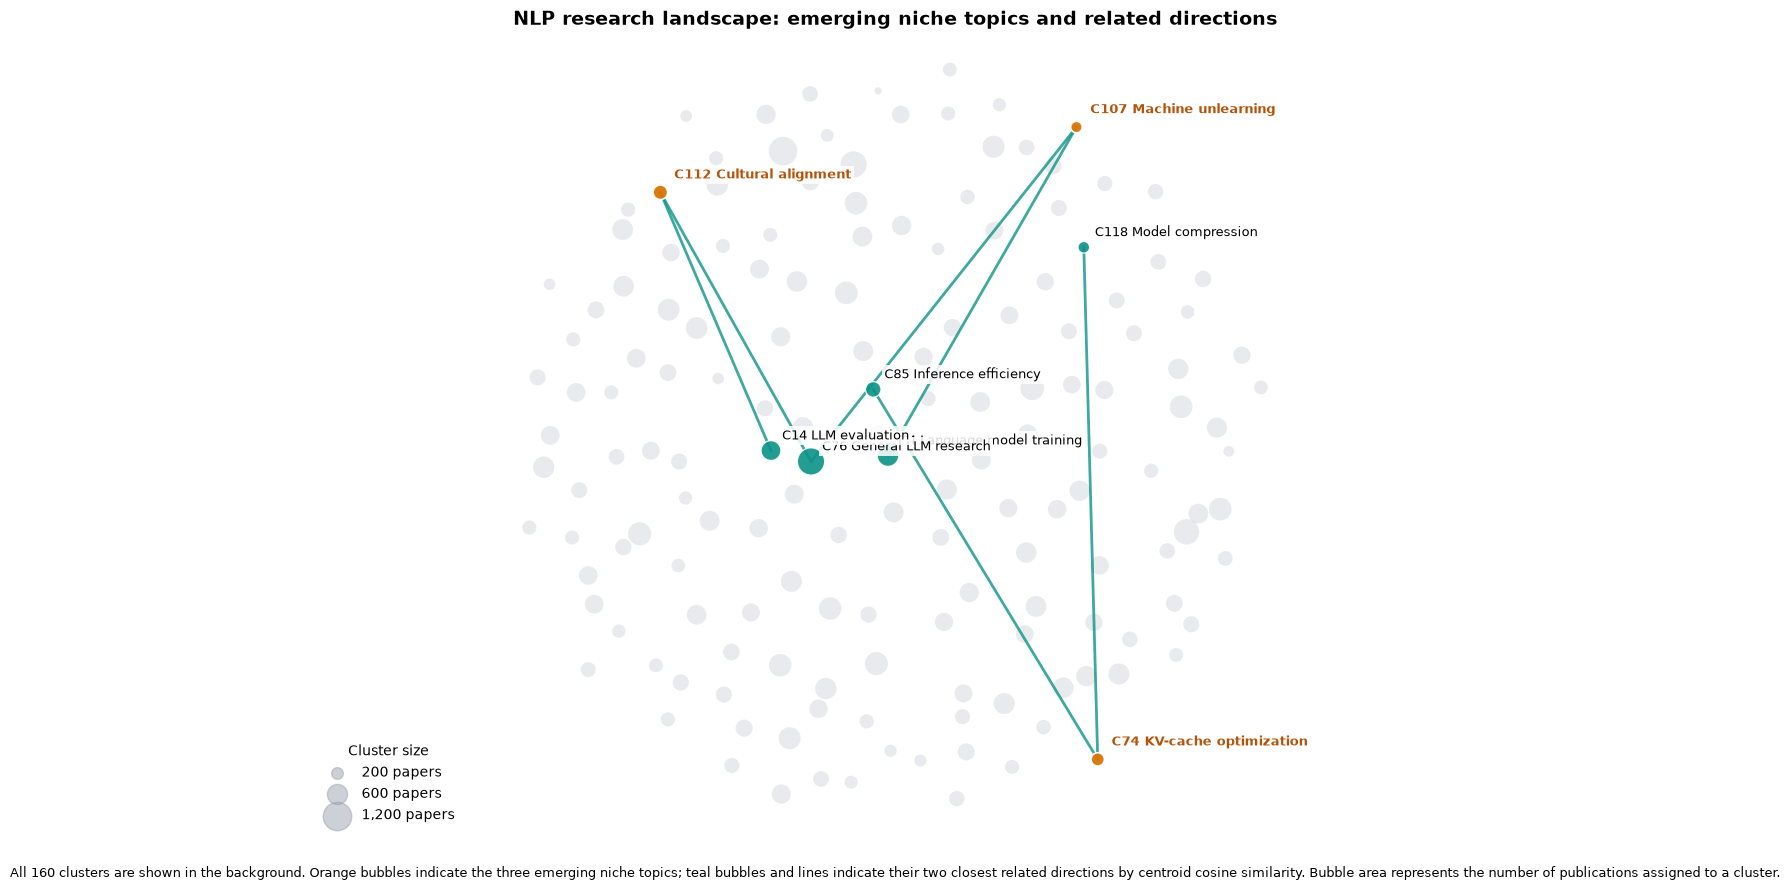

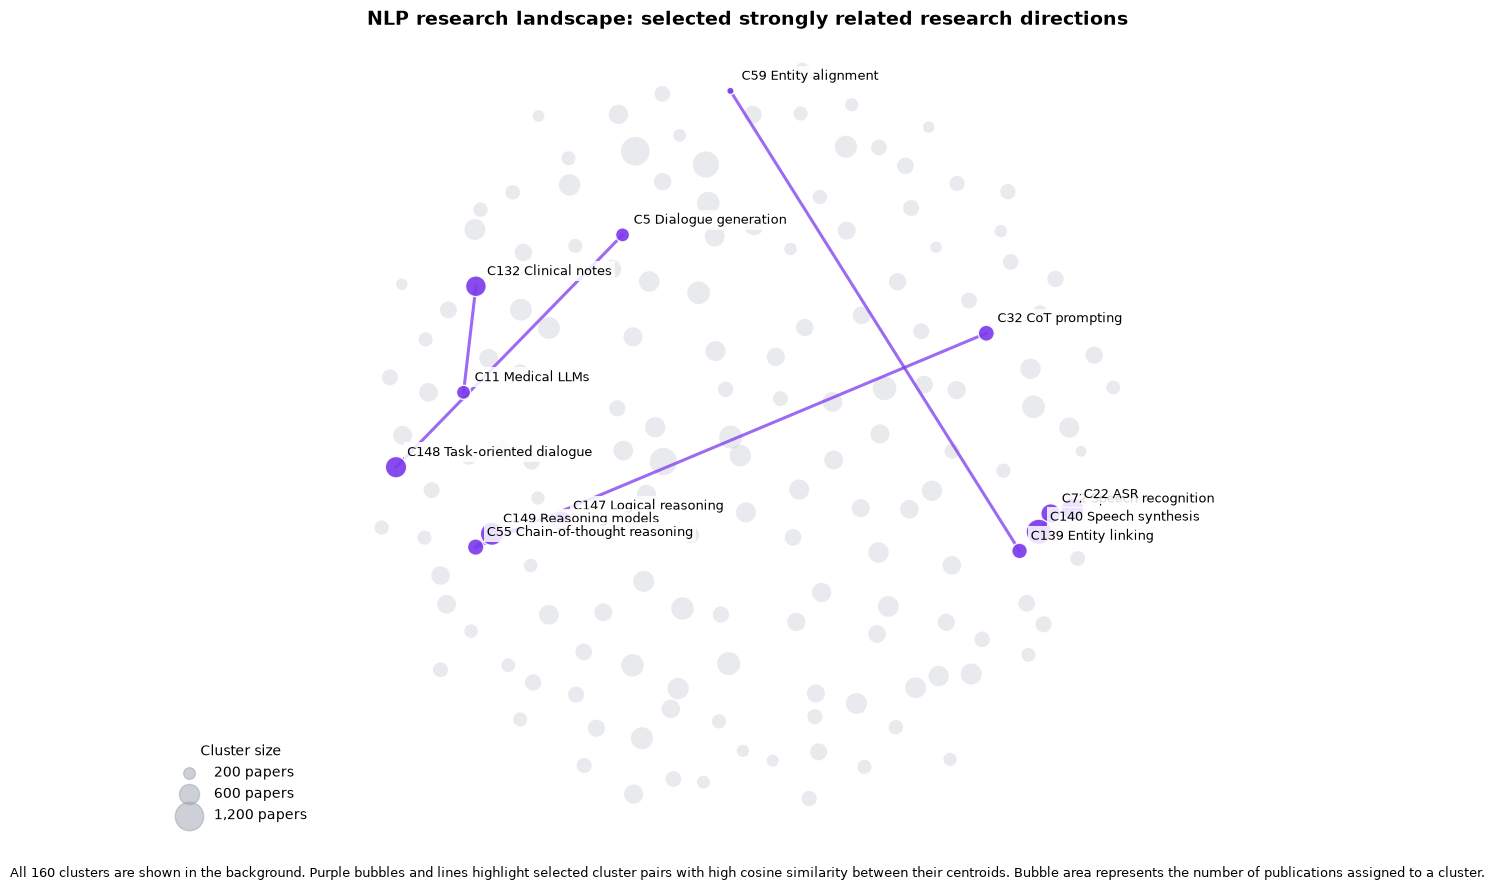

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import MDS

# -----------------------------
# Load cluster sizes
# -----------------------------
counts = pd.read_csv(
    artifacts / "final_document_clusters.csv",
    usecols=["cluster_id"]
)["cluster_id"].value_counts().sort_index()

n_clusters = similarity.shape[0]

# ensure all cluster ids exist in the size vector
counts = counts.reindex(range(n_clusters), fill_value=0)

# -----------------------------
# Global 2D projection for all 160 clusters
# -----------------------------
S = np.clip(similarity, -1, 1)
D = np.sqrt(np.maximum(0, 2 * (1 - S)))
np.fill_diagonal(D, 0)

mds = MDS(
    n_components=2,
    dissimilarity="precomputed",
    random_state=42,
    n_init=4,
    max_iter=300
)
xy = mds.fit_transform(D)

# Optional projection quality check
original = D[np.triu_indices(n_clusters, 1)]
projected_D = np.sqrt(((xy[:, None, :] - xy[None, :, :]) ** 2).sum(axis=2))
projected = projected_D[np.triu_indices(n_clusters, 1)]
dist_corr = np.corrcoef(original, projected)[0, 1]
print("2D versus original distance correlation:", round(dist_corr, 3))

# -----------------------------
# Cluster labels used in charts
# -----------------------------
labels = {
    74: "KV-cache optimization",
    85: "Inference efficiency",
    118: "Model compression",
    107: "Machine unlearning",
    4: "Language model training",
    76: "General LLM research",
    112: "Cultural alignment",
    14: "LLM evaluation",
    100: "Human–LLM cognition",
    147: "Logical reasoning",
    149: "Reasoning models",
    55: "Chain-of-thought reasoning",
    32: "CoT prompting",
    22: "ASR",
    72: "Speech recognition",
    140: "Speech synthesis",
    11: "Medical LLMs",
    132: "Clinical notes",
    5: "Dialogue generation",
    148: "Task-oriented dialogue",
    59: "Entity alignment",
    139: "Entity linking",
}

# -----------------------------
# Selections
# -----------------------------
# niche topics and their nearest related directions
niche_topics = {
    74: [85, 118],
    107: [4, 76],
    112: [76, 14]
}

# strongest high-similarity examples
strong_pairs = [
    (147, 149),   # logical reasoning / reasoning models
    (55, 149),    # CoT reasoning / reasoning models
    (32, 55),     # CoT prompting / CoT reasoning
    (22, 72),     # ASR / speech recognition
    (72, 140),    # speech recognition / speech synthesis
    (11, 132),    # medical LLMs / clinical notes
    (5, 148),     # dialogue generation / task-oriented dialogue
    (59, 139),    # entity alignment / entity linking
]

# -----------------------------
# Styling helpers
# -----------------------------
sizes = counts.to_numpy() * 0.35

def draw_base(ax, title):
    ax.scatter(
        xy[:, 0], xy[:, 1],
        s=sizes,
        color="#9ca3af",
        alpha=0.22,
        edgecolors="none",
        zorder=1
    )
    # bubble size legend
    for n in [200, 600, 1200]:
        ax.scatter([], [], s=n * 0.35, color="#9ca3af", alpha=0.5,
                   label=f"{n:,} papers")
    ax.legend(title="Cluster size", loc="lower left", frameon=False)
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_aspect("equal", adjustable="datalim")
    ax.axis("off")

def annotate_cluster(ax, cid, color="black", weight="normal", dx=8, dy=8):
    ax.annotate(
        f"C{cid} {labels.get(cid, str(cid))}",
        (xy[cid, 0], xy[cid, 1]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=9,
        color=color,
        fontweight=weight,
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2),
        zorder=6
    )


# Niche topics in landscape
fig, ax = plt.subplots(figsize=(12, 9))
draw_base(ax, "NLP research landscape: emerging niche topics and related directions")

# related directions
related_ids = set()
for src, nbrs in niche_topics.items():
    for tgt in nbrs:
        related_ids.add(tgt)
        ax.plot(
            xy[[src, tgt], 0], xy[[src, tgt], 1],
            color="#0d9488",
            linewidth=2,
            alpha=0.8,
            zorder=3
        )

ax.scatter(
    xy[list(related_ids), 0], xy[list(related_ids), 1],
    s=sizes[list(related_ids)],
    color="#0d9488",
    alpha=0.9,
    edgecolor="white",
    linewidth=0.9,
    zorder=4
)

# niche topics
niche_ids = list(niche_topics.keys())
ax.scatter(
    xy[niche_ids, 0], xy[niche_ids, 1],
    s=sizes[niche_ids],
    color="#d97706",
    alpha=0.95,
    edgecolor="white",
    linewidth=1.2,
    zorder=5
)

# labels
for cid in niche_ids:
    annotate_cluster(ax, cid, color="#b45309", weight="bold", dx=10, dy=10)
for cid in related_ids:
    annotate_cluster(ax, cid, dx=8, dy=8)

fig.text(
    0.5, 0.02,
    "All 160 clusters are shown in the background. Orange bubbles indicate the three emerging niche topics; "
    "teal bubbles and lines indicate their two closest related directions by centroid cosine similarity. "
    "Bubble area represents the number of publications assigned to a cluster.",
    ha="center", fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(artifacts / "niche_landscape.png", dpi=300, bbox_inches="tight")
plt.show()

# Strong established connections

fig, ax = plt.subplots(figsize=(12, 9))
draw_base(ax, "NLP research landscape: selected strongly related research directions")

selected_ids = set()
for a, b in strong_pairs:
    selected_ids.update([a, b])
    ax.plot(
        xy[[a, b], 0], xy[[a, b], 1],
        color="#7c3aed",
        linewidth=2.2,
        alpha=0.75,
        zorder=3
    )

ax.scatter(
    xy[list(selected_ids), 0], xy[list(selected_ids), 1],
    s=sizes[list(selected_ids)],
    color="#7c3aed",
    alpha=0.9,
    edgecolor="white",
    linewidth=1.0,
    zorder=4
)

for cid in selected_ids:
    annotate_cluster(ax, cid, dx=8, dy=8)

fig.text(
    0.5, 0.02,
    "All 160 clusters are shown in the background. Purple bubbles and lines highlight selected cluster pairs "
    "with high cosine similarity between their centroids. Bubble area represents the number of publications "
    "assigned to a cluster.",
    ha="center", fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(artifacts / "high_similarity_landscape.png", dpi=300, bbox_inches="tight")
plt.show()